Agentic RAG with LangGraph

In [1]:
import os
from typing import List, TypedDict

from dotenv import load_dotenv
from google import genai
from google.genai import types
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_core.embeddings import Embeddings
from langgraph.graph import END, StateGraph
from sentence_transformers import SentenceTransformer


C:\Users\Asus\AppData\Local\Temp\ipykernel_10020\4011949911.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS
c:\Users\Asus\RAG\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [24]:
load_dotenv()

True

In [25]:
class LocalSentenceTransformerEmbeddings(Embeddings):
    def __init__(self, model_name: str = "all-MiniLM-L6-v2") -> None:
        self.model_name = model_name
        self.model = SentenceTransformer(model_name)

    def embed_documents(self, texts: List[str]) -> List[List[float]]:
        vectors = self.model.encode(texts, convert_to_numpy=True)
        return vectors.tolist()

    def embed_query(self, text: str) -> List[float]:
        vector = self.model.encode(text, convert_to_numpy=True)
        return vector.tolist()


gemini_api_key = os.getenv("GEMINI_API_KEY")
if not gemini_api_key:
    raise ValueError("GEMINI_API_KEY is not set. Load your .env file or set it before running this notebook.")

gemini_model = os.getenv("GEMINI_MODEL", "gemini-3.1-flash-lite")
client = genai.Client(api_key=gemini_api_key)
embeddings = LocalSentenceTransformerEmbeddings()


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3240.62it/s]


In [26]:
print(f"Gemini model: {gemini_model}")
print(f"Embedding model: {embeddings.model_name}")


Gemini model: gemini-3.1-flash-lite
Embedding model: all-MiniLM-L6-v2


State Definition

In [27]:
class AgentState(TypedDict):
    question: str
    documents: List[Document]
    answer: str
    needs_retrieval: bool


In [30]:
### Sample Documents and Vector Store Creation
sample_docs = [
    "AgentState is a class that represents the state of an agent in a retrieval-augmented generation (RAG) system. It contains the following attributes: question, documents, answer, and needs_retrieval.",
    "Artificial intelligence (AI) is a branch of computer science that aims to create machines capable of intelligent behavior. It encompasses various subfields, including machine learning, natural language processing, and robotics.",
    "Machine learning is a subset of AI that focuses on the development of algorithms that allow computers to learn from and make predictions or decisions based on data. It involves training models on large datasets to recognize patterns and improve performance over time.",
    "LLM (large language model) is a type of machine learning model that is trained on vast amounts of text data to understand and generate human-like language. LLMs can perform a variety of natural language processing tasks, such as text generation, translation, summarization, and question answering.",
]

documents = [Document(page_content=doc) for doc in sample_docs]
vector_store = FAISS.from_documents(documents, embeddings)
retriever = vector_store.as_retriever(search_kwargs={"k": 2})


Agents Function

In [29]:
def decide_retrieval(state: AgentState) -> AgentState:
    """
    Decide whether to perform retrieval based on the current state.
    For example, if the answer is empty or if the question is new, we may want to retrieve documents.
    """

    question = state["question"]
    retrieval_keywords = ["what", "how", "why", "explain", "define", "describe"]
    needs_retrieval = any(keyword in question.lower() for keyword in retrieval_keywords) or not state.get("answer")

    return {**state, "needs_retrieval": needs_retrieval}

In [31]:
def retrieve_documents(state: AgentState) -> AgentState:
    """
    Retrieve documents based on the current state.
    If retrieval is needed, use the retriever to fetch relevant documents.
    """
    question = state["question"]
    documents = retriever.invoke(question)

    return {**state, "documents": documents}


In [44]:
def generate_answer(state: AgentState) -> AgentState:
    """
    Generate an answer based on the current state.
    If retrieval is needed, use the retrieved documents to generate a more informed answer.
    """
    question = state["question"]
    documents = state.get("documents", [])

    # Create a prompt for the Gemini model
    context = "\n".join([doc.page_content for doc in documents])
    prompt = f"Based on the following context answer the question, Question: {question}\nContext: {context}\nAnswer:"

    response = client.interactions.create(
        model=gemini_model,
        input=prompt,
    )


    answer = response.output_text.strip()
    return {**state, "answer": answer}

Conditional Logic

In [33]:
def should_retrieve(state: AgentState) -> bool:
    """
    Determine if retrieval is needed based on the current state.
    """
    if state['needs_retrieval']:
        return 'retrieve'
    else:
        return 'generate_answer'
    

Build the Graph

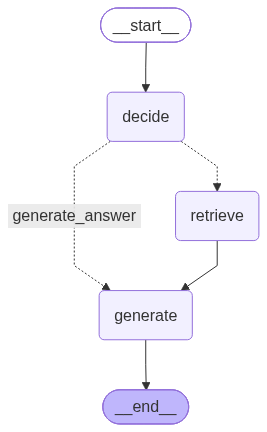

In [45]:
workflow = StateGraph(AgentState)

workflow.add_node("decide", decide_retrieval)
workflow.add_node("retrieve", retrieve_documents)
workflow.add_node("generate", generate_answer)

workflow.set_entry_point("decide")

workflow.add_conditional_edges(
    'decide',
    should_retrieve,
    {
        'retrieve': 'retrieve',
        'generate_answer': 'generate'
    }
)

workflow.add_edge('retrieve', 'generate')
workflow.add_edge('generate', END)

app = workflow.compile()
app

Test

In [35]:
def ask_question(question: str) -> str:
    """
    Ask a question to the agent and get an answer.
    """
    initial_state: AgentState = {
        "question": question,
        "documents": [],
        "answer": "",
        "needs_retrieval": False
    }

    final_state = app.invoke(initial_state)
    return final_state["answer"]

In [46]:
question = "What is AgentState in the context of RAG?"
answer = ask_question(question)
print(f"Question: {question}\nAnswer: {answer}")

Question: What is AgentState in the context of RAG?
Answer: Answer: In the context of RAG, AgentState is a class that represents the state of an agent. It includes four specific attributes: question, documents, answer, and needs_retrieval.
